In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv('FYP_Cleaned_Dataset.csv', parse_dates=['Datetime'])
print(f"Dataset loaded successfully with {df.shape[0]} rows and {df.shape[1]} columns.")

print(df.info())

Dataset loaded successfully with 1314360 rows and 20 columns.
<class 'pandas.DataFrame'>
RangeIndex: 1314360 entries, 0 to 1314359
Data columns (total 20 columns):
 #   Column                  Non-Null Count    Dtype         
---  ------                  --------------    -----         
 0   Datetime                1314360 non-null  datetime64[us]
 1   State                   1314360 non-null  str           
 2   Latitude                1314360 non-null  float64       
 3   Longitude               1314360 non-null  float64       
 4   GHI_W_m2                1314360 non-null  float64       
 5   Cloud_Coverage_Pct      1314360 non-null  float64       
 6   Temp_Skin_C             1314360 non-null  float64       
 7   Relative_Humidity_Pct   1314360 non-null  float64       
 8   Wind_Speed_10m_m_s      1314360 non-null  float64       
 9   Wind_Direction_10m_deg  1314360 non-null  float64       
 10  Precipitable_Water_cm   1314360 non-null  float64       
 11  Hour                    1

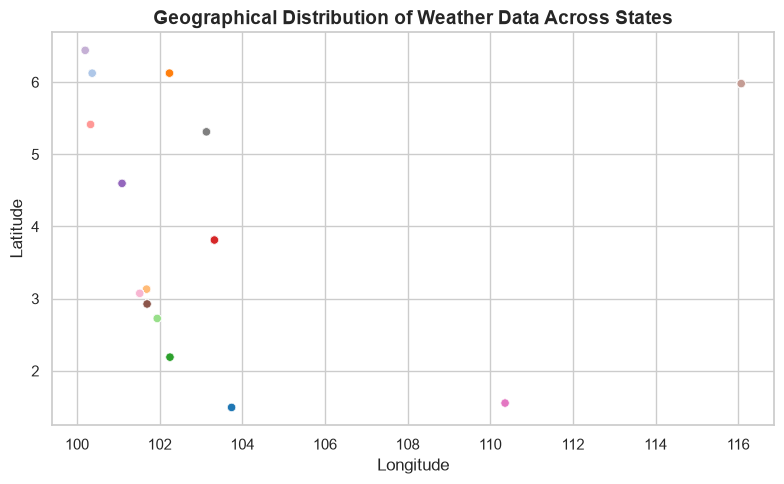

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 5))
sns.scatterplot(x='Longitude', y='Latitude', hue='State', data=df, palette='tab20', legend=False)
plt.title('Geographical Distribution of Weather Data Across States', fontsize=14, fontweight='bold')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.tight_layout()
plt.show()

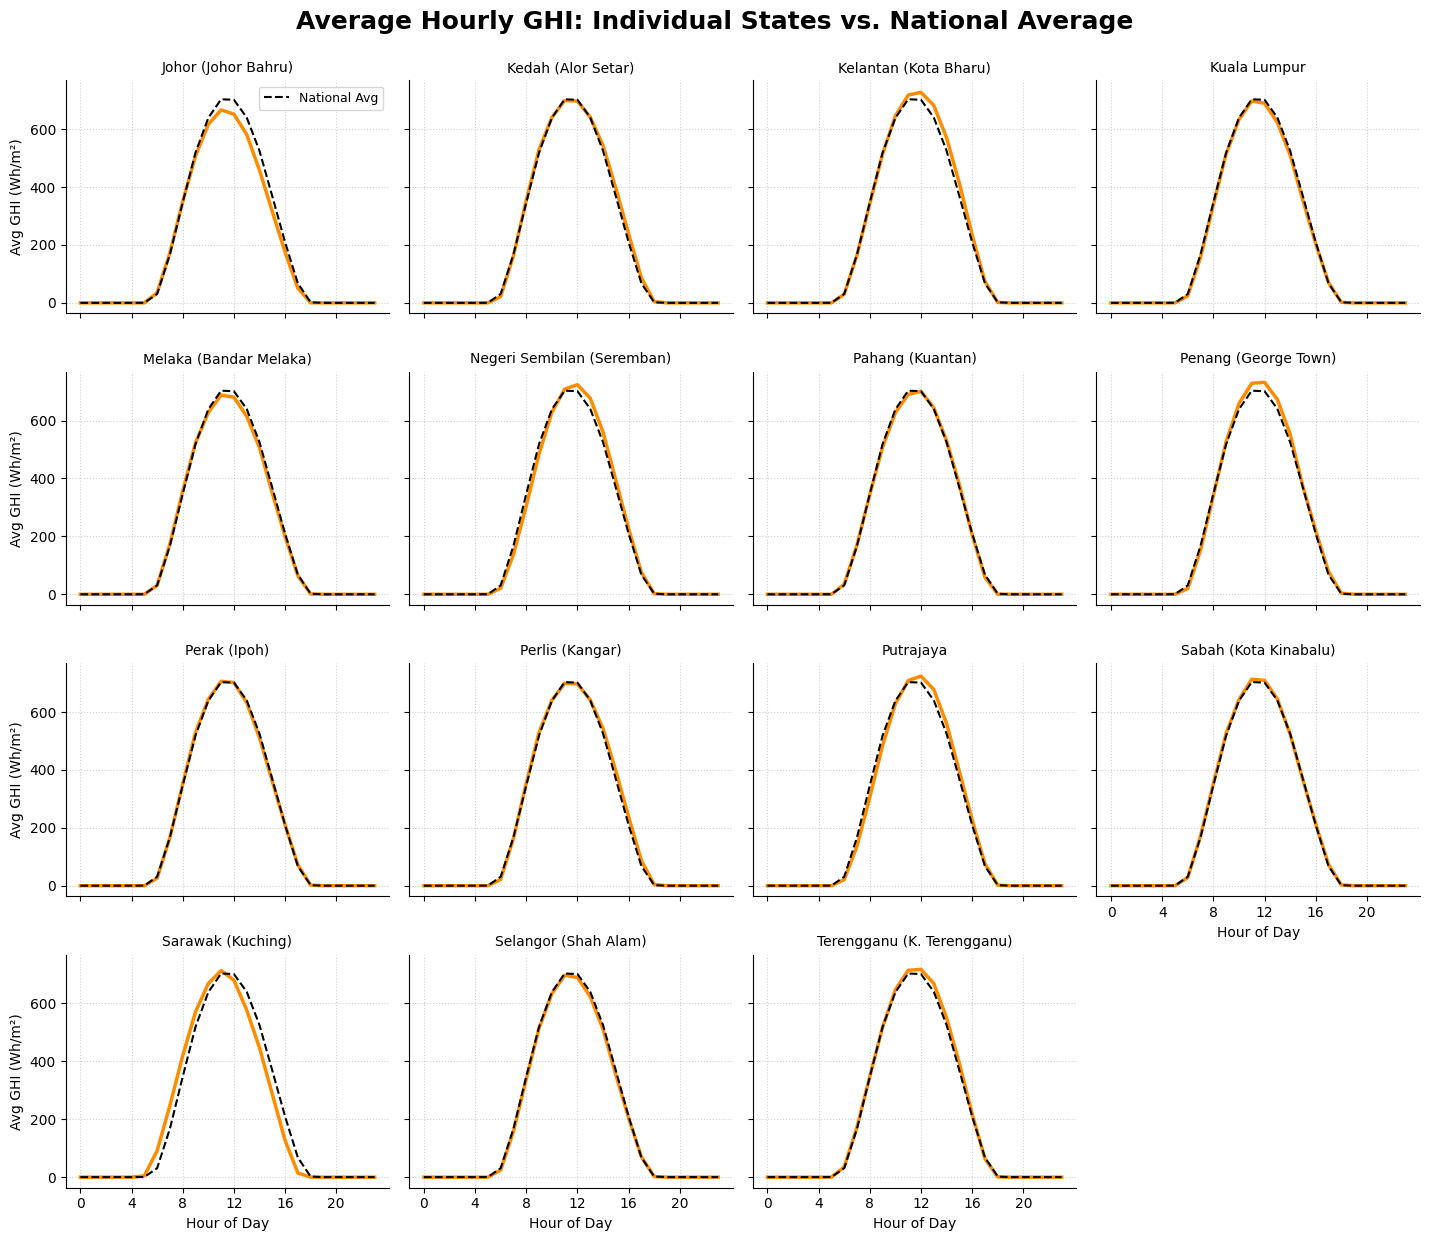

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Extract hour if not already available
df['Hour'] = pd.to_datetime(df['Datetime']).dt.hour

# 2. Compute the INDIVIDUAL STATE average GHI by hour
state_hourly_avg = df.groupby(['Hour', 'State'])['GHI_W_m2'].mean().reset_index()

# 3. Compute the OVERALL national average GHI by hour (for reference)
overall_hourly_avg = df.groupby('Hour')['GHI_W_m2'].mean().reset_index()

# 4. Create a grid of separate graphs (FacetGrid) for each state
g = sns.relplot(
    data=state_hourly_avg,
    x='Hour',
    y='GHI_W_m2',
    col='State',       
    col_wrap=4,       
    kind='line',
    color='darkorange',
    linewidth=2.5,
    height=3,         
    aspect=1.2       
)

# 5. Overlay the National Average on every single graph
for ax in g.axes.flat:
    # Draw the dashed black line for the national average
    ax.plot(overall_hourly_avg['Hour'], overall_hourly_avg['GHI_W_m2'], 
            color='black', linestyle='--', linewidth=1.5, label='National Avg')
    
    # Clean up the look of each small chart
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.set_xticks(range(0, 24, 4)) 

# 6. Add a main title and clean up the labels
g.fig.suptitle('Average Hourly GHI: Individual States vs. National Average', fontsize=18, fontweight='bold', y=1.03)
g.set_titles("{col_name}") 
g.set_axis_labels("Hour of Day", "Avg GHI (W/m²)")

g.axes[0].legend(fontsize=9)

plt.show()

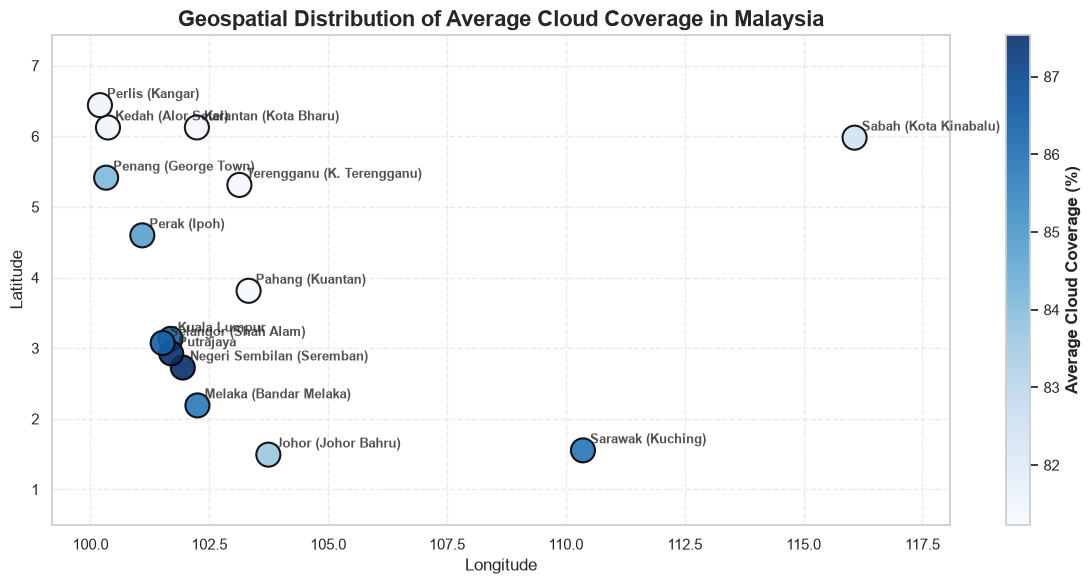

In [4]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Calculate the average cloud coverage for each state/location
# (Plotting thousands of hours at once will just create overlapping dots)
avg_cloud_df = df.groupby(['State', 'Latitude', 'Longitude'])['Cloud_Coverage_Pct'].mean().reset_index()

# 2. Set up the plot
plt.figure(figsize=(12, 6))

# 3. Create the scatter plot where color = Cloud Coverage
scatter = plt.scatter(x=avg_cloud_df['Longitude'], 
                      y=avg_cloud_df['Latitude'], 
                      c=avg_cloud_df['Cloud_Coverage_Pct'], 
                      cmap='Blues',       # Uses a blue gradient just like your image
                      s=300,              # Make the dots large and readable
                      alpha=0.9,          # Slight transparency
                      edgecolor='black',  # Clean black border around the dots
                      linewidth=1.5)

# 4. Add a colorbar to explain what the colors mean
cbar = plt.colorbar(scatter)
cbar.set_label('Average Cloud Coverage (%)', fontsize=12, fontweight='bold')

# 5. Add State Labels next to the dots so the examiner knows which is which
for i, row in avg_cloud_df.iterrows():
    plt.text(row['Longitude'] + 0.15, row['Latitude'] + 0.1, row['State'], 
             fontsize=9, fontweight='bold', alpha=0.8)

# 6. Formatting
plt.title('Geospatial Distribution of Average Cloud Coverage in Malaysia', fontsize=16, fontweight='bold')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.grid(True, linestyle='--', alpha=0.4)

# Force the axes to wrap tightly around Malaysia
plt.xlim(avg_cloud_df['Longitude'].min() - 1, avg_cloud_df['Longitude'].max() + 2)
plt.ylim(avg_cloud_df['Latitude'].min() - 1, avg_cloud_df['Latitude'].max() + 1)

plt.tight_layout()
plt.show()

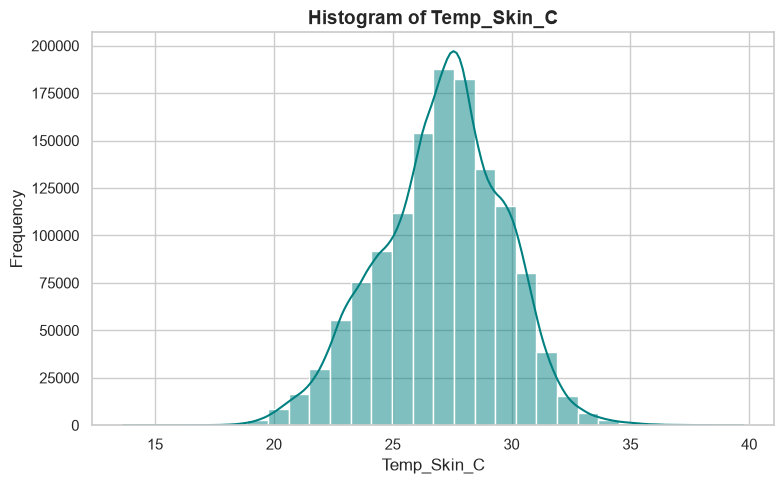

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 5))
sns.histplot(df['Temp_Skin_C'], kde=True, bins=30, color='teal')
plt.title('Histogram of Temp_Skin_C', fontsize=14, fontweight='bold')
plt.xlabel('Temp_Skin_C')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

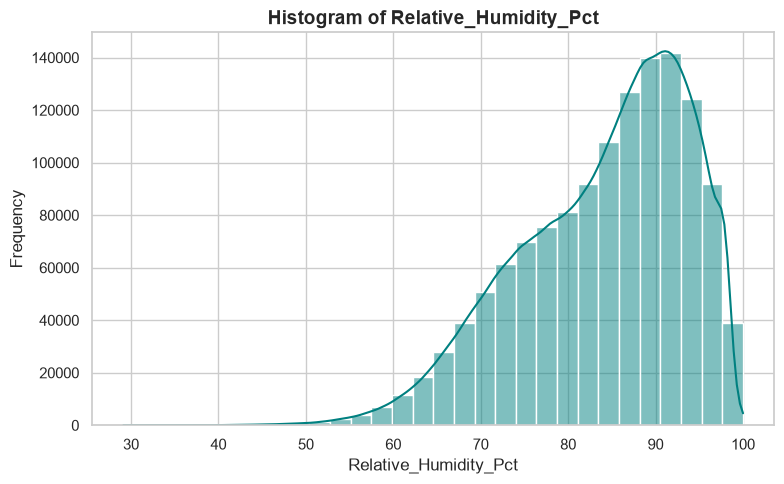

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 5))
sns.histplot(df['Relative_Humidity_Pct'], kde=True, bins=30, color='teal')
plt.title('Histogram of Relative_Humidity_Pct', fontsize=14, fontweight='bold')
plt.xlabel('Relative_Humidity_Pct')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

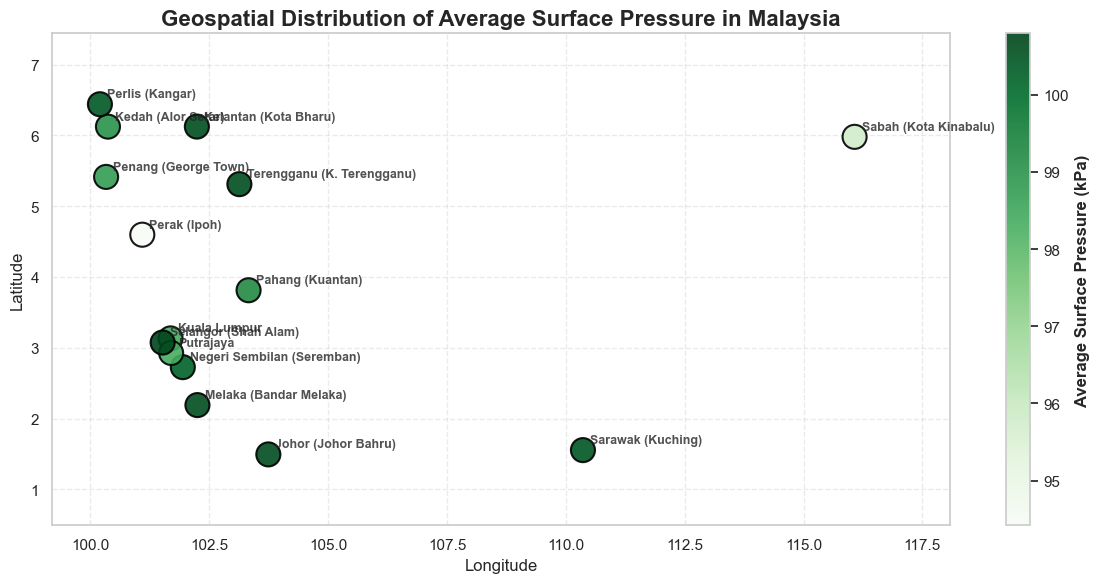

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Calculate the average surface pressure for each state/location
avg_pressure_df = df_cleaned.groupby(['State', 'Latitude', 'Longitude'])['Surface_Pressure_kPa'].mean().reset_index()

# 2. Set up the plot
plt.figure(figsize=(12, 6))

# 3. Create the scatter plot where color = Surface Pressure
scatter = plt.scatter(x=avg_pressure_df['Longitude'], 
                      y=avg_pressure_df['Latitude'], 
                      c=avg_pressure_df['Surface_Pressure_kPa'], 
                      cmap='Greens',      # Uses a green gradient to match your earlier pressure charts!
                      s=300,              # Make the dots large and readable
                      alpha=0.9,          # Slight transparency
                      edgecolor='black',  # Clean black border around the dots
                      linewidth=1.5)

# 4. Add a colorbar to explain what the colors mean
cbar = plt.colorbar(scatter)
cbar.set_label('Average Surface Pressure (kPa)', fontsize=12, fontweight='bold')

# 5. Add State Labels next to the dots
for i, row in avg_pressure_df.iterrows():
    plt.text(row['Longitude'] + 0.15, row['Latitude'] + 0.1, row['State'], 
             fontsize=9, fontweight='bold', alpha=0.8)

# 6. Formatting
plt.title('Geospatial Distribution of Average Surface Pressure in Malaysia', fontsize=16, fontweight='bold')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.grid(True, linestyle='--', alpha=0.4)

# Force the axes to wrap tightly around Malaysia
plt.xlim(avg_pressure_df['Longitude'].min() - 1, avg_pressure_df['Longitude'].max() + 2)
plt.ylim(avg_pressure_df['Latitude'].min() - 1, avg_pressure_df['Latitude'].max() + 1)

plt.tight_layout()
plt.show()

In [ ]:
print(df_cleaned.columns.tolist())

['Datetime', 'State', 'Latitude', 'Longitude', 'GHI_kWh_m2', 'Cloud_Coverage_Pct', 'Temp_Air_2m_C', 'Temp_Skin_C', 'Relative_Humidity_Pct', 'Surface_Pressure_kPa', 'Wind_Speed_10m_m_s', 'Precipitable_Water_cm', 'Is_Daylight', 'Hour_sin', 'Hour_cos', 'Wind_Sine', 'Wind_Cosine', 'Rainfall_mm_log']


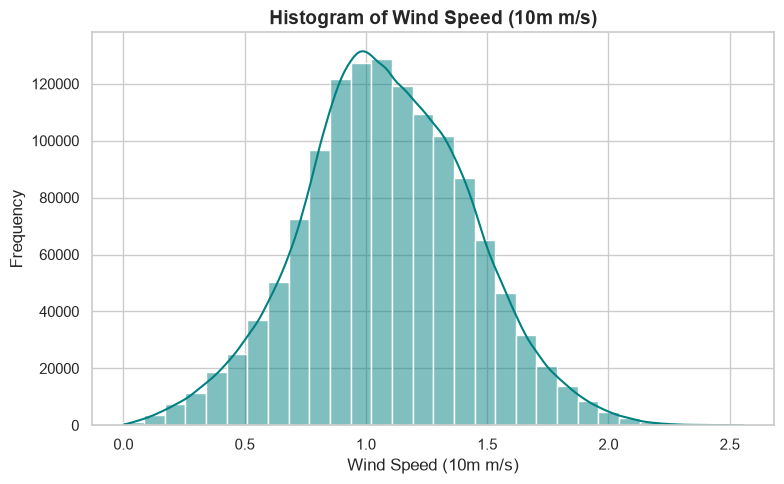

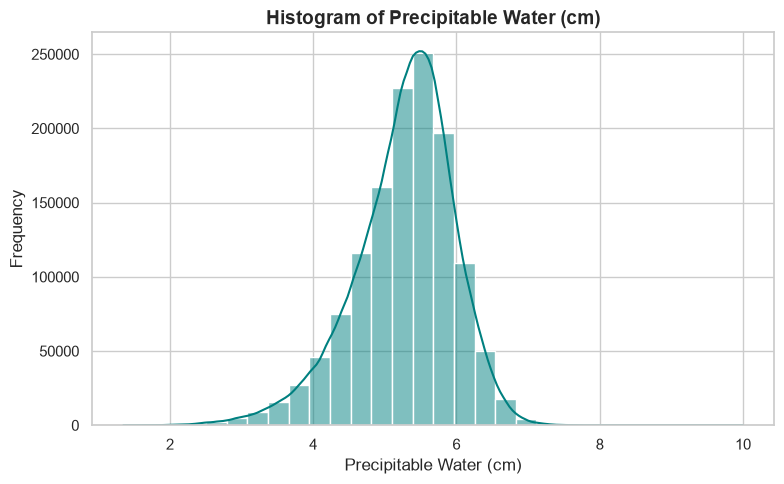

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Wind Speed
plt.figure(figsize=(8, 5))
sns.histplot(df_cleaned['Wind_Speed_10m_m_s_log'], kde=True, bins=30, color='teal')
plt.title('Histogram of Wind Speed (10m m/s)', fontsize=14, fontweight='bold')
plt.xlabel('Wind Speed (10m m/s)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

# Precipitable Water
plt.figure(figsize=(8, 5))
sns.histplot(df_cleaned['Precipitable_Water_cm'], kde=True, bins=30, color='teal')
plt.title('Histogram of Precipitable Water (cm)', fontsize=14, fontweight='bold')
plt.xlabel('Precipitable Water (cm)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

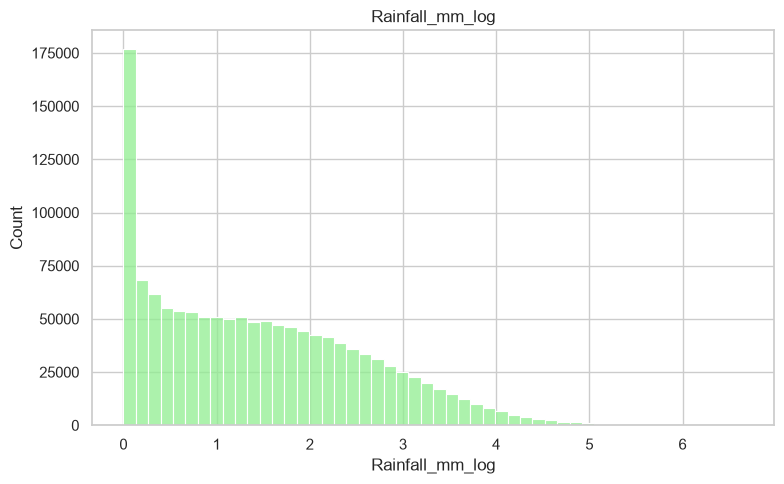

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(df['Rainfall_mm_log'], bins=50, color='lightgreen')
plt.title('Rainfall_mm_log')
plt.xlabel('Rainfall_mm_log')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

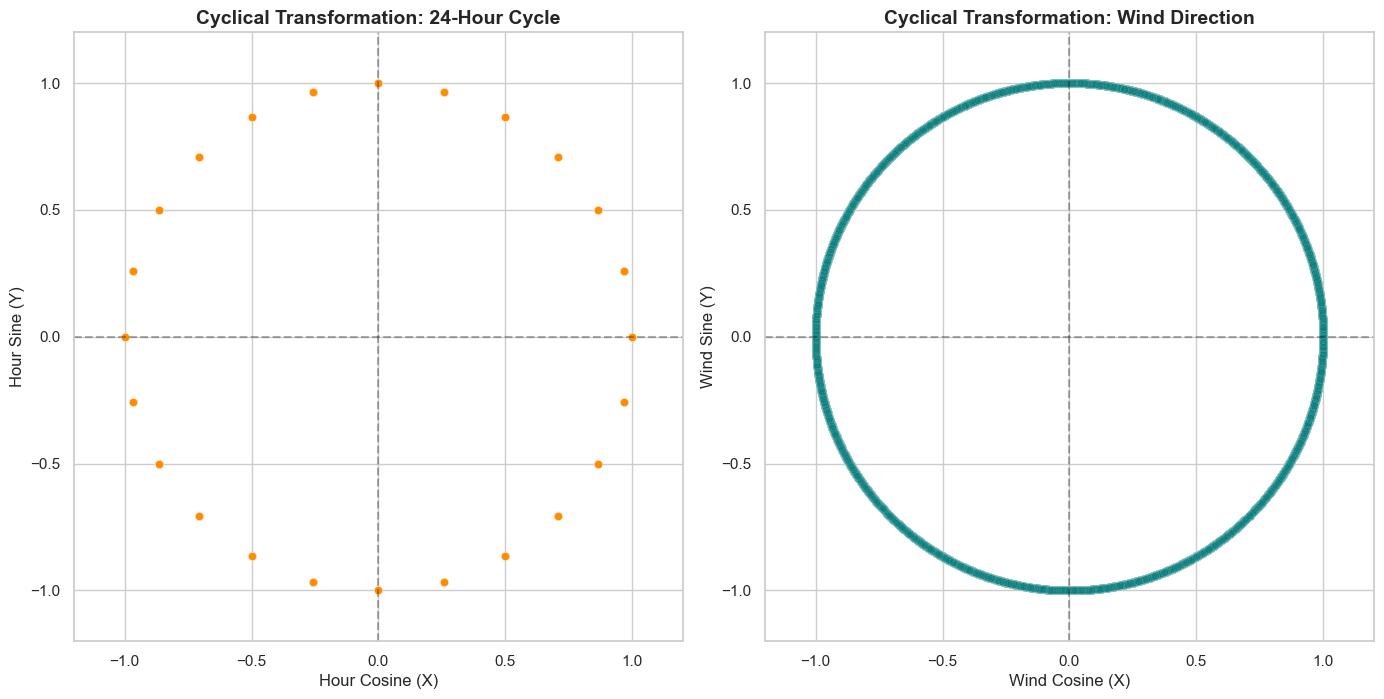

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set up a side-by-side figure
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

# Plot 1: The 24-Hour Cycle
# We use a scatter plot to map Cosine (X) vs Sine (Y)
sns.scatterplot(x='Hour_cos', y='Hour_sin', data=df_cleaned, 
                color='darkorange', alpha=0.5, ax=axes[0])

# Formatting the Hour Clock
axes[0].set_title('Cyclical Transformation: 24-Hour Cycle', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Hour Cosine (X)')
axes[0].set_ylabel('Hour Sine (Y)')
axes[0].axhline(0, color='black', linestyle='--', alpha=0.3) # Draw X axis
axes[0].axvline(0, color='black', linestyle='--', alpha=0.3) # Draw Y axis
axes[0].set_aspect('equal') # Forces the plot to be a perfect square so the circle doesn't look like an oval
axes[0].set_xlim(-1.2, 1.2)
axes[0].set_ylim(-1.2, 1.2)

# Plot 2: The Wind Direction Cycle
# We use a lower alpha (transparency) because there are thousands of overlapping wind data points!
sns.scatterplot(x='Wind_Cosine', y='Wind_Sine', data=df_cleaned, 
                color='teal', alpha=0.05, ax=axes[1])

# Formatting the Wind Compass
axes[1].set_title('Cyclical Transformation: Wind Direction', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Wind Cosine (X)')
axes[1].set_ylabel('Wind Sine (Y)')
axes[1].axhline(0, color='black', linestyle='--', alpha=0.3) # Draw X axis
axes[1].axvline(0, color='black', linestyle='--', alpha=0.3) # Draw Y axis
axes[1].set_aspect('equal') # Forces perfect circle
axes[1].set_xlim(-1.2, 1.2)
axes[1].set_ylim(-1.2, 1.2)

plt.tight_layout()
plt.show()